In [1]:
from uf3_handler import *
import shutil

class UF3FileHandler:
    def __init__(self, path):
        self.path = path
    def clear_directory(self):
        for file in os.listdir(self.path):
            os.remove(os.path.join(self.path, file))
    def get_files(self):
        return os.listdir(self.path)
    def get_file(self, filename):
        return os.path.join(self.path, filename)
    def backup_directory(self, backup_path):
        os.makedirs(backup_path, exist_ok=True)
        shutil.copytree(self.path, backup_path)
    
        


class ModelAutomater:
    def __init__(self, directories, run_data_path, feature_filename, element_list, degree, chemical_system, maps, num_cores):
         # Class-wide LUT for filter types to corresponding methods
        self.FILTER_FUNCTION_LUT = {
            'composition': 'filter_composition',
            'energy_above_hull': 'filter_energy_above_hull',
            'maximum_force': 'filter_force',
            'zero_force': 'remove_zero_force',
            'none': 'get_data'
            # Add new filters here as needed
        }
        
        self.directories = directories
        self.run_data_path = run_data_path
        self.feature_filename = feature_filename
        self.element_list = element_list
        self.degree = degree
        self.chemical_system = chemical_system
        self.maps = maps
        self.num_cores = num_cores
        self.pickle_directory = 'data/pickle_files/'
        self.filter_directory = 'data/pickle_files/filtered/'
        self.feature_directory = 'data/featurized/'
        
        #init variables
        self.feature_batch_size = 500
        self.data_coordinator = io.DataCoordinator()
        self.base_data_labels = []
        self.base_data_frames = {}
        self.filtered_data_frames = {}
        self.filtered_data_labels = []
        self.feature_paths = {}
        self.model_data = pd.DataFrame()
        self.data_ignore_list = []
        
        # Load existing data
        self.load_existing_base_data()
        self.load_existing_features()
        

    def load_existing_data(self, directory):
        """
        Load existing data from the specified directory, ignoring files that match data types in data_ignore_list.
        """
        data_parser = DataParser(directory, self.data_coordinator)
        data_files = {}
        local_data_labels = []
        for file in os.listdir(directory):
            if file.endswith('.pkl'):
                # Extract the data type from the file name and check against the ignore list
                data_type = file.replace('.pkl', '')
                data_type = data_type.replace('_filtered', '')
                if data_type in self.data_ignore_list:
                    continue
                data_parser.load_from_pickle(directory + file)
                data_files[file] = data_parser.get_data()
                local_data_labels.append(file)
        return data_files, local_data_labels
    def replace_existing_data(self, filename, data):
        filepath = os.path.join(self.pickle_directory, filename)
        parser = DataParser('', self.data_coordinator)
        parser.set_data(data)
        parser.export_to_pickle(filepath)
        
    def load_single_pickle_file(self, file_path):
        data_parser = DataParser('', self.data_coordinator)
        data_parser.load_from_pickle(file_path)
        return data_parser.get_data()
                
    def load_new_base_data(self):
        for directory in self.directories:
            data_parser = DataParser(directory, self.data_coordinator)
            data_parser.parse_directories(output=True, filter=True)
            # Export to pickle with the same name as the directory
            filename = directory.split('/')[-1]
            data_parser.export_to_pickle(self.pickle_directory + filename + '.pkl')
        self.load_existing_data()

    def load_existing_base_data(self):
        """
        Load base data while ignoring data types in data_ignore_list.
        """
        self.base_data_labels = []
        self.base_data_frames = {}
        data_files, local_data_labels = self.load_existing_data(self.pickle_directory)
        self.base_data_labels += local_data_labels
        self.base_data_frames.update(data_files)
        for file in data_files:
            # Check and load corresponding feature files
            data_type = file.replace('.pkl', '')
            if data_type in self.data_ignore_list:
                continue
            feature_file = f'df_features_{data_type}.h5'
            feature_path = os.path.join(self.feature_directory, feature_file)
            if os.path.exists(feature_path):
                self.feature_paths[file] = feature_path
            else:
                print(f"Warning: No feature file found for {file}")

    def get_data(self):
        return self.data_frames
    
    def get_feature_paths(self):
        return self.feature_paths

    def load_existing_features(self):
        """
        Load feature files, ignoring those corresponding to data types in data_ignore_list.
        """
        for file in os.listdir(self.feature_directory):
            if file.endswith('.h5'):
                data_type = file.replace('df_features_', '').replace('.h5', '')
                if data_type in self.data_ignore_list:
                    continue
                pickle_file_name = f'{data_type}.pkl'
                if pickle_file_name in self.base_data_frames:
                    self.feature_paths[pickle_file_name] = os.path.join(self.feature_directory, file)
                else:
                    print(f"Warning: Feature file {file} does not have a corresponding pickle file.")

    def generate_new_features(self):
        """
        Generate feature files for all data frames, excluding data types in data_ignore_list.
        """
        for label, data in self.base_data_frames.items():
            data_type = label.replace('.pkl', '')
            if data_type in self.data_ignore_list:
                continue
            output_file = f'df_features_{data_type}.h5'
            featurizer = Featurizer(data, self.chemical_system, self.maps)
            featurizer.featurize_data(self.num_cores, output_file, self.feature_batch_size)
        self.load_existing_features()
    def clear_filtered_data(self):
        UF3FileHandler(self.filter_directory).clear_directory()
        self.filtered_data_labels = []
        self.filtered_data_frames = {}
    def load_filtered_data(self):
        """
            Load filtered data from the filter directory. This data will actually be used for training/testing
        """
        self.filtered_data_labels = []
        self.filtered_data_frames = {}
        data_files, local_data_labels = self.load_existing_data(self.filter_directory)
        self.filtered_data_labels += local_data_labels
        self.filtered_data_frames.update(data_files)
    def check_structure_data(self, data):
        """
        Check for the presence of necessary data columns: eah and element fractions.
        
        Parameters:
        - data: DataFrame containing the structure data to check.
        
        Returns:
        - bool: True if all necessary data is present, False otherwise.
        """
        
        # Check for the existence of the 'eah' column
        if 'eah' not in data.columns:
            print('No eah data found')
            return False
        
        # Check for element fraction columns based on self.element_list
        missing_elements = []
        for element in self.element_list:
            if f'{element}_frac' not in data.columns:
                missing_elements.append(element)
        
        if missing_elements:
            print(f"Missing fraction data for elements: {', '.join(missing_elements)}")
            return False
        
        return True
    def repair_structure_data(self, data):
        print("Repairing structure data...")
        sp = StructureParser(data)
        return sp.get_data()
    def generate_new_filtered_data(self, data_type, filter_type, check_existing=True, *args ):
        """
        Generate new filtered data based on the data type and filter type provided.
        
        Parameters:
        - data_type: 'structures', 'temperature', 'pressure', etc.
        - filter_type: 'composition', 'energy_above_hull', 'maximum_force', etc.
        - args: Additional arguments for the specific filter.
        - check_existing: Boolean flag to check for existing filtered files before filtering.
        """
        filtered_filename = f'{data_type}_filtered.pkl'
        filtered_file_path = os.path.join(self.filter_directory,  filtered_filename)
        # Load the appropriate data
        if check_existing:
            #check if the filtered file is already in the filtered_data_frames
            if  filtered_filename in self.filtered_data_frames:
                data = self.filtered_data_frames[filtered_filename]
        else:
            data_filename = f'{data_type}.pkl'
            if data_filename not in self.base_data_frames:
                print(f"No data loaded for {data_type}.")
                return
            data = self.base_data_frames[data_filename]
            # Check for the appropriate data columns
            if data_type == 'structure':
                if not self.check_structure_data(data):
                    data = self.repair_structure_data(data)
                    self.replace_existing_data(data_filename, data)
                    

            
        
        
                
        # Create a DataFilter instance
        data_filter = DataFilter(data)
        print(f"Filtering {data_type} data with {filter_type} filter.")
        print(f"Current data length: {len(data)}")
        
        # Find the appropriate filter method
        filter_method_name = self.FILTER_FUNCTION_LUT.get(filter_type)
        if not filter_method_name:
            print(f"Unsupported filter type: {filter_type}")
            return
        
        # Get the filter method from the DataFilter instance
        filter_method = getattr(data_filter, filter_method_name, None)
        if not filter_method:
            print(f"Filter method {filter_method_name} not found in DataFilter.")
            return
        
        # Apply the filter with the provided arguments
        filter_method(*args)
        
        # Export the filtered data to a new pickle file in the filtered directory
        data_filter.export_to_pickle(filtered_file_path)
        
        print(f"Filtered data length: {len(data_filter.get_data())}")
        
        # Reload the filtered data
        self.load_filtered_data()
    def copy_unfiltered_data(self):
        """
        Copy unfiltered data to the filtered directory, excluding data types in data_ignore_list.
        """
        for label, data in self.base_data_frames.items():
            data_type = label.replace('.pkl', '')
            if data_type in self.data_ignore_list:
                continue
            filtered_label = label.replace('.pkl', '_filtered.pkl')
            if filtered_label not in self.filtered_data_labels:
                data_parser = DataParser('', self.data_coordinator)
                data_parser.set_data(data)
                data_parser.export_to_pickle(os.path.join(self.filter_directory, filtered_label))
    def clear_memory(self):
        """
        Clear all data from memory.
        """
        self.base_data_labels = []
        self.base_data_frames = {}
        self.filtered_data_frames = {}
        self.filtered_data_labels = []
    def clear_ignore_list(self):
        self.data_ignore_list = []
    def add_to_ignore_list(self, data_label):
        self.data_ignore_list.append(data_label)
    def consolidate_data(self):
        """
        Consolidate all data into a single DataFrame for training/testing, ignoring data types in data_ignore_list.
        """
        self.load_filtered_data()
        consolidated_data = pd.DataFrame()
        for label, data in self.filtered_data_frames.items():
            data_type = label.replace('.pkl', '').replace('_filtered', '')
            if data_type in self.data_ignore_list:
                continue
            consolidated_data = pd.concat([consolidated_data, data], ignore_index=False)
        print(f"Consolidated data length: {len(consolidated_data)}")
        self.clear_memory()
        self.model_data = consolidated_data
    def get_unique_indices(self, data):
        """
        Get the unique indices in the DataFrame.

        :return: List of unique indices.
        """
        return data.index.to_series().apply(lambda x: '_'.join(x.split('_')[:2])).unique()
    def split_data(self, test_percent=0.2):
        """
        Split the data into training and testing sets.
        
        Parameters:
        - test_percent: Fraction of data to use for testing.
        """
        index_prefixes = self.get_unique_indices(self.model_data)
        np.random.seed(42)  # for reproducibility
        num_indices_to_select = int(test_percent * len(index_prefixes))
        selected_prefixes = np.random.choice(index_prefixes, num_indices_to_select, replace=False)

        # Filter data for testing set based on the selected prefixes
        self.testing_set = self.model_data[self.model_data.index.to_series().apply(lambda x: '_'.join(x.split('_')[:2])).isin(selected_prefixes)]
        self.test_keys = self.testing_set.index

        # Filter data for training set
        self.training_set = self.model_data[~self.model_data.index.isin(self.testing_set.index)]
        self.train_keys= self.training_set.index
        print(f"Training set length: {len(self.training_set)}. Testing set length: {len(self.testing_set)}")
        return self.training_set, self.testing_set
       
    def train_model(self, model_filename, training_data, testing_data, regularizer, weight=0.3, batch_size=2500):
        """
        Train a model using the given data.
        
        Parameters:
        - regularizer: Regularization parameter for the model.
        - weight: Class weight for the model.
        - batch_size: Batch size for training.
        """
        #get the actual data from self.feature_paths
        features = []
        for key in self.feature_paths:
            features.append(self.feature_paths[key])
        #find the structures feature file
        for feature in features:
            if 'structure' in feature:
                structure_feature = feature
                break
        trainer = ModelTrainer(self.model_data, self.chemical_system, self.maps, regularizer)
        trainer.set_training_set(training_data)
        print(f"trainer training length: {len(trainer.get_training_set())}")
        trainer.set_testing_set(testing_data)
        print(f"trainer testing length: {len(trainer.get_testing_set())}")
        trainer.train_model_multiple_files(features, weight, batch_size)
        trainer.export_model(model_filename + ".json")
        analyzer = ModelAnalyzer(self.chemical_system, trainer.get_model(), trainer.get_bspline_config(), training_data, testing_data, structure_feature)
        return analyzer
    def store_validation_data(self, model_filename, validation_data):
        """
        Store the validation data for a given model.
        """
        #store the validation data in potentials folder
        with open(f'potentials/{model_filename}_validation_data.txt', 'w') as f:
            f.write(str(validation_data))
    def run_grid_search(self, composition_element, composition_range, energy_range, force_range, regularizer_ranges):
        """
        Run a grid search to find the best hyperparameters for the model, including the regularizer values.
        """

        for composition in composition_range:
            for energy in energy_range:
                for force in force_range:
                    for ridge_1b in regularizer_ranges['ridge_1b']:
                        for ridge_2b in regularizer_ranges['ridge_2b']:
                            for ridge_3b in regularizer_ranges['ridge_3b']:
                                for curvature_2b in regularizer_ranges['curvature_2b']:
                                    for curvature_3b in regularizer_ranges['curvature_3b']:
                                        print(f"Running grid search for composition={composition}, energy={energy}, force={force}, "
                                            f"ridge_1b={ridge_1b}, ridge_2b={ridge_2b}, ridge_3b={ridge_3b}, "
                                            f"curvature_2b={curvature_2b}, curvature_3b={curvature_3b}")
                                        
                                        model_filename = (f'composition_{composition}_energy_{energy}_force_{force}_'
                                                        f'ridge1b_{ridge_1b}_ridge2b_{ridge_2b}_ridge3b_{ridge_3b}_'
                                                        f'curv2b_{curvature_2b}_curv3b_{curvature_3b}')
                                        
                                        # Set the current regularizer values
                                        regularizer = dict(ridge_1b=ridge_1b,
                                                        ridge_2b=ridge_2b,
                                                        ridge_3b=ridge_3b,
                                                        curvature_2b=curvature_2b,
                                                        curvature_3b=curvature_3b)
                                        
                                        # Clear memory and load base data
                                        self.clear_memory()
                                        self.load_existing_base_data()
                                        
                                        # Generate filtered data
                                        self.generate_new_filtered_data('structure', 'composition', False, composition_element, composition)
                                        self.generate_new_filtered_data('structure', 'energy_above_hull', True, energy)
                                        self.generate_new_filtered_data('structure', 'maximum_force', True, force, force, force)
                                        
                                        # Consolidate data
                                        self.consolidate_data()
                                        
                                        # Split data into training and testing sets
                                        training, testing = self.split_data(0.2)
                                        
                                        # Train the model with the current parameters and regularizers
                                        analyzer = self.train_model(model_filename + ".json", training, testing, regularizer)
                                        
                                        # Export model to LAMMPS format
                                        analyzer.export_model_to_lammps("potentials/", model_filename, "ntaormina", "metal", "nk")
                                        analyzer.export_model_to_lammps(os.getcwd(), model_filename, "ntaormina", "metal", "nk")
                                        
                                        # Validate the model
                                        validation_data = analyzer.validate_potential("v1", model_filename, ['Al', 'N'])
                                        print(f"Model {model_filename} validation data: {validation_data}")
                                        
                                        # Store validation data
                                        self.store_validation_data(model_filename, validation_data)
                                        
                                        # Remove potential file from current working directory
                                        os.remove(f"{model_filename}")

        
        
        
        


# --------------USER INPUTS----------------
directories = ['/blue/ypchen/ntaormina/uf3/AlN/garun_7_9_2024_12_14_29/temp', '/blue/ypchen/ntaormina/uf3/AlN/pressure_variation_data', '/blue/ypchen/ntaormina/uf3/AlN/temp_variation_data']
run_data_path = '/blue/ypchen/ntaormina/uf3/AlN/garun_7_9_2024_12_14_29/run_data'
feature_filename = 'df_features_all_data.h5'
element_list = ['Al', 'N']
degree = 3
chemical_system = composition.ChemicalSystem(element_list=element_list,
                                             degree=degree)
r_min_map = {}
for pair in chemical_system.interactions_map[2]:
    r_min_map[pair] = 0.001
    
for trio in chemical_system.interactions_map[3]:
    r_min_map[trio] = [1.5,1.5,1.5]
r_max_map = {}
for pair in chemical_system.interactions_map[2]:
    r_max_map[pair] = 7.0
    
for trio in chemical_system.interactions_map[3]:
    r_max_map[trio] = [3.5,3.5,7.0]
r_resolution_map = {}
for pair in chemical_system.interactions_map[2]:
    r_resolution_map[pair] = 25
    
for trio in chemical_system.interactions_map[3]:
    r_resolution_map[trio] = [8,8,16]
trailing_trim = 3
leading_trim = 0
maps = {}
maps['r_min_map'] = r_min_map
maps['r_max_map'] = r_max_map
maps['r_resolution_map'] = r_resolution_map
maps['trailing_trim'] = trailing_trim
maps['leading_trim'] = leading_trim
regularizer =  dict(ridge_1b=1e-6,
                    ridge_2b=0.0,
                    ridge_3b=1e-6,
                    curvature_2b=5e-7,
                    curvature_3b=1e-7)
regularizer_ranges = {
    'ridge_1b': [0],
    'ridge_2b': [1e-8],
    'ridge_3b': [1e-7],
    'curvature_2b': [1e-6],
    'curvature_3b': [1e-5]
}

automater = ModelAutomater(directories, run_data_path, feature_filename, element_list, degree, chemical_system, maps, 6)
# automater.add_to_ignore_list('pressure')
# automater.add_to_ignore_list('temp')
automater.clear_memory()
automater.load_existing_base_data()
automater.load_existing_features()
automater.run_grid_search('N', [0.8], [3], [20], regularizer_ranges)
# automater.generate_new_filtered_data('structure', 'composition', False, 'N', 0.7)
# automater.generate_new_filtered_data('structure', 'energy_above_hull', True, 2)
# automater.generate_new_filtered_data('structure', 'maximum_force', True, 20, 20, 20)
# automater.generate_new_filtered_data('structure', 'zero_force', True)
# automater.generate_new_filtered_data('pressure', 'zero_force', True)
# automater.generate_new_filtered_data('temp', 'zero_force', True)
# automater.copy_unfiltered_data()
# automater.consolidate_data()
# training, testing = automater.split_data(0.2)

# automater.train_model('test_model', training, testing, regularizer)


/home/ntaormina/miniconda38/envs/uf3_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DataFrame has been loaded from data/pickle_files/pressure.pkl
DataFrame has been loaded from data/pickle_files/structure.pkl
DataFrame has been loaded from data/pickle_files/temp.pkl
DataFrame has been loaded from data/pickle_files/pressure.pkl
DataFrame has been loaded from data/pickle_files/structure.pkl
DataFrame has been loaded from data/pickle_files/temp.pkl
Running grid search for composition=0.8, energy=3, force=20, ridge_1b=0, ridge_2b=1e-08, ridge_3b=1e-07, curvature_2b=1e-06, curvature_3b=1e-05
DataFrame has been loaded from data/pickle_files/pressure.pkl
DataFrame has been loaded from data/pickle_files/structure.pkl
DataFrame has been loaded from data/pickle_files/temp.pkl
Filtering structure data with composition filter.
Current data length: 34630
Filtering out data with over 80.0% N composition.
DataFrame has been saved to data/pickle_files/filtered/structure_filtered.pkl
Filtered data length: 16859
DataFrame has been loaded from data/pickle_files/filtered/pressure_filtere

100%|██████████| 102/102 [03:10<00:00,  1.87s/it]


Model has been exported to composition_0.8_energy_3_force_20_ridge1b_0_ridge2b_1e-08_ridge3b_1e-07_curv2b_1e-06_curv3b_1e-05.json.json


***Add the following line to the LAMMPS input script***


pair_style	uf3 3 2
pair_coeff	* * potentials/composition_0.8_energy_3_force_20_ridge1b_0_ridge2b_1e-08_ridge3b_1e-07_curv2b_1e-06_curv3b_1e-05_20240823_162842 N Al


Citation meta-data has been left blank. Please enter appropriate citation for the generated UF3 LAMMPS potential




***Add the following line to the LAMMPS input script***


pair_style	uf3 3 2
pair_coeff	* * /blue/ypchen/ntaormina/uf3/AlN/test_auto/UF3-Tools/composition_0.8_energy_3_force_20_ridge1b_0_ridge2b_1e-08_ridge3b_1e-07_curv2b_1e-06_curv3b_1e-05 N Al


Citation meta-data has been left blank. Please enter appropriate citation for the generated UF3 LAMMPS potential


/blue/ypchen/ntaormina/uf3/AlN/test_auto/UF3-Tools/validation
parent_directory=lammps
Parent directory: /blue/ypchen/ntaormina/uf3/AlN/test_auto/UF3-Tools/vali

DataFrame has been loaded from data/pickle_files/filtered/filtered_data_eah_2.pkl
Training set length: 7975. Testing set length: 2454
Training set columns: Index(['geometry', 'energy', 'fx', 'fy', 'fz', 'size', 'pde', 'eah', 'Al_frac',
       'N_frac'],
      dtype='object')


100%|██████████| 21/21 [01:54<00:00,  5.44s/it]


Model has been exported to test_model


100%|██████████| 1000/1000 [00:04<00:00, 208.67it/s]


    Smallest observed: 0.00 angstroms
    Suggested Cutoffs: [3.385 3.45  3.485 3.535 3.625 3.725 3.82  3.88  3.945 4.005 4.035 4.065
 4.095 4.125 4.165 4.215 4.245 4.3   4.37  4.425 4.5   4.555 4.58  4.655
 4.765 4.84  4.89  4.97  5.115 5.245 5.325 5.385 5.445 5.52  5.59  5.635
 5.66  5.7   5.765 5.855 5.925 5.965 6.035 6.095 6.16  6.255 6.36  6.465
 6.515 6.545 6.575 6.615 6.695 6.775 6.815 6.84  6.865 6.915 6.965 7.015
 7.115 7.215 7.29  7.365 7.435 7.545 7.67  7.765 7.86  7.92  8.025 8.155
 8.22  8.26  8.285 8.305 8.35  8.415 8.455 8.545 8.645 8.685 8.73  8.77
 8.845 8.93  8.97  9.    9.025 9.065 9.105 9.135 9.175 9.215 9.255 9.285
 9.33  9.395 9.435 9.475 9.55  9.64  9.74  9.83  9.925]
    Smallest observed: 1.50 angstroms
    Suggested Cutoffs: [3.295 3.47  3.58  3.655 3.77  3.885 3.925 3.99  4.08  4.145 4.225 4.3
 4.4   4.51  4.605 4.675 4.735 4.835 4.925 4.985 5.025 5.055 5.09  5.15
 5.225 5.275 5.32  5.395 5.47  5.52  5.555 5.63  5.695 5.73  5.775 5.825
 5.865 5.905 5.945 5.97

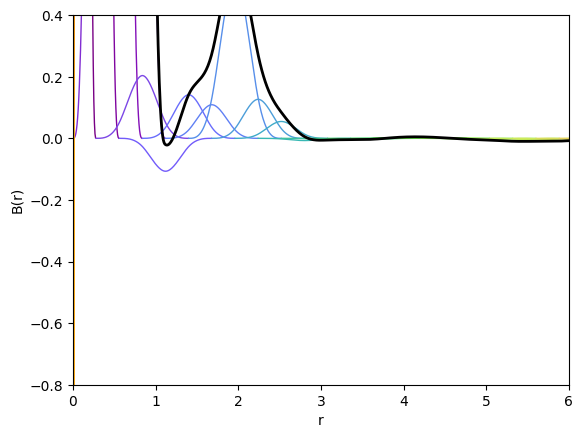

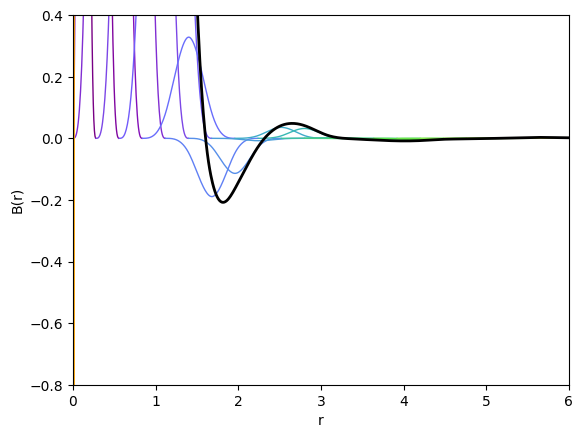

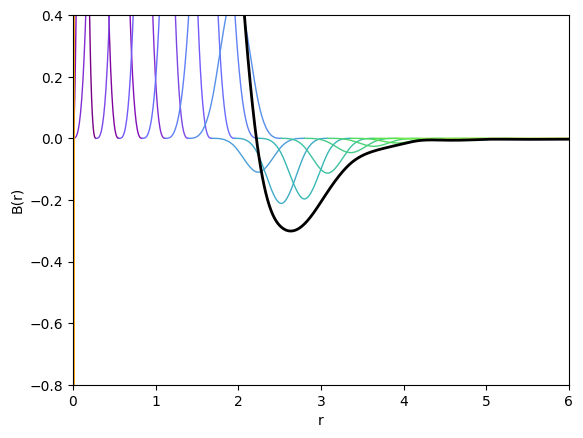

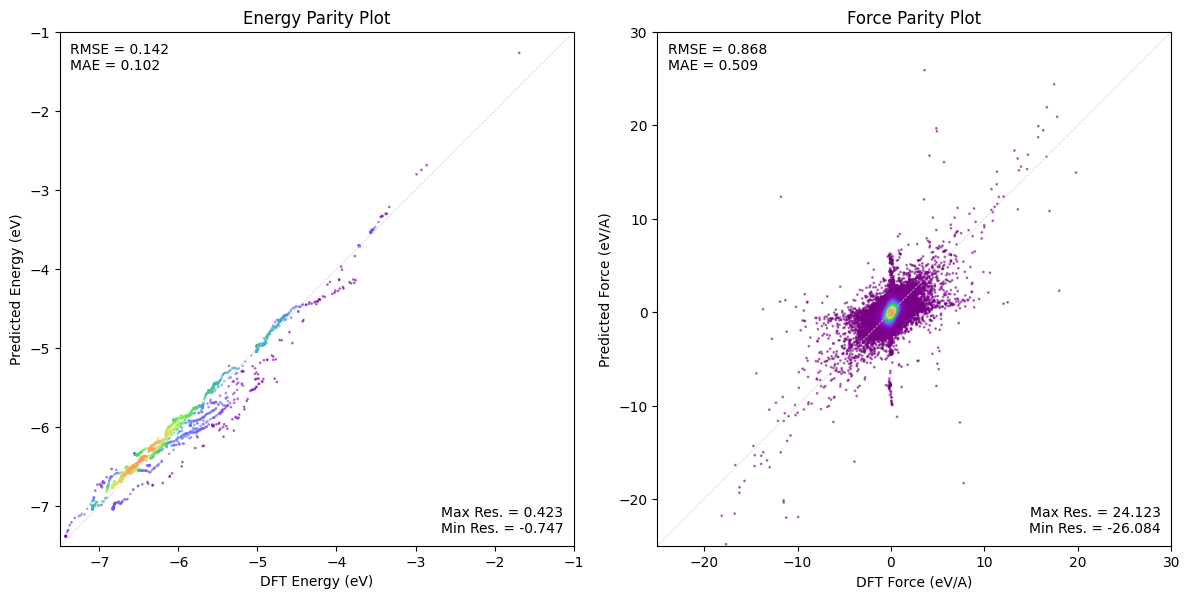

100%|██████████| 1000/1000 [00:04<00:00, 215.54it/s]


    Smallest observed: 0.00 angstroms
    Suggested Cutoffs: [3.345 3.405 3.445 3.5   3.57  3.62  3.66  3.695 3.745 3.815 3.855 3.93
 4.03  4.105 4.205 4.32  4.425 4.495 4.57  4.675 4.765 4.845 4.905 4.99
 5.12  5.235 5.345 5.445 5.52  5.58  5.615 5.665 5.715 5.745 5.775 5.795
 5.825 5.87  5.94  6.005 6.07  6.155 6.245 6.365 6.465 6.56  6.68  6.765
 6.825 6.88  6.915 6.94  7.005 7.065 7.085 7.21  7.34  7.38  7.42  7.48
 7.54  7.565 7.615 7.725 7.815 7.855 7.895 7.955 8.015 8.075 8.145 8.185
 8.215 8.285 8.38  8.445 8.485 8.53  8.595 8.66  8.71  8.75  8.825 8.915
 8.955 8.985 9.045 9.1   9.14  9.23  9.31  9.345 9.39  9.435 9.485 9.555
 9.63  9.715 9.8   9.88 ]
    Smallest observed: 1.42 angstroms
    Suggested Cutoffs: [3.34  3.51  3.58  3.655 3.72  3.805 3.93  4.02  4.08  4.165 4.22  4.255
 4.305 4.39  4.455 4.5   4.56  4.6   4.635 4.695 4.755 4.84  4.975 5.06
 5.095 5.15  5.23  5.315 5.395 5.465 5.535 5.63  5.715 5.805 5.88  5.935
 5.995 6.055 6.14  6.21  6.245 6.29  6.365 6.465 6.53

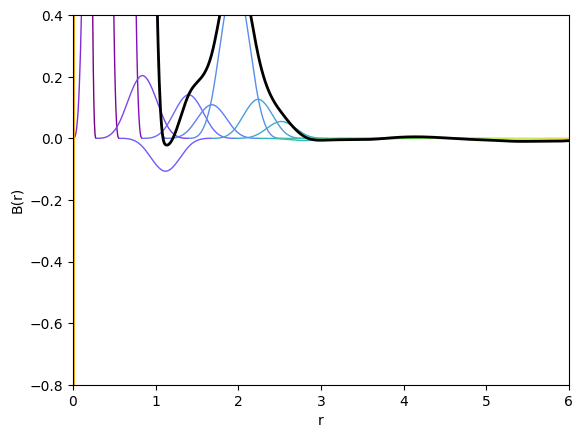

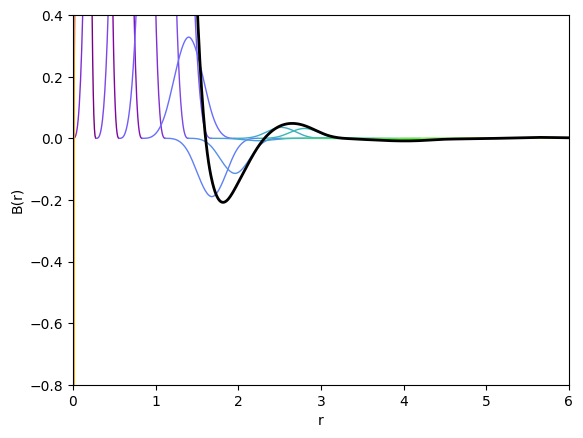

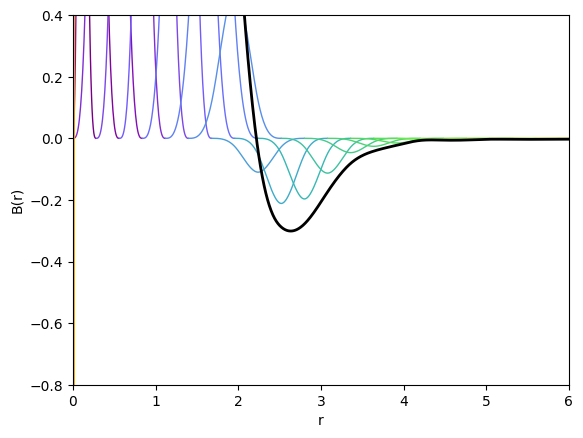

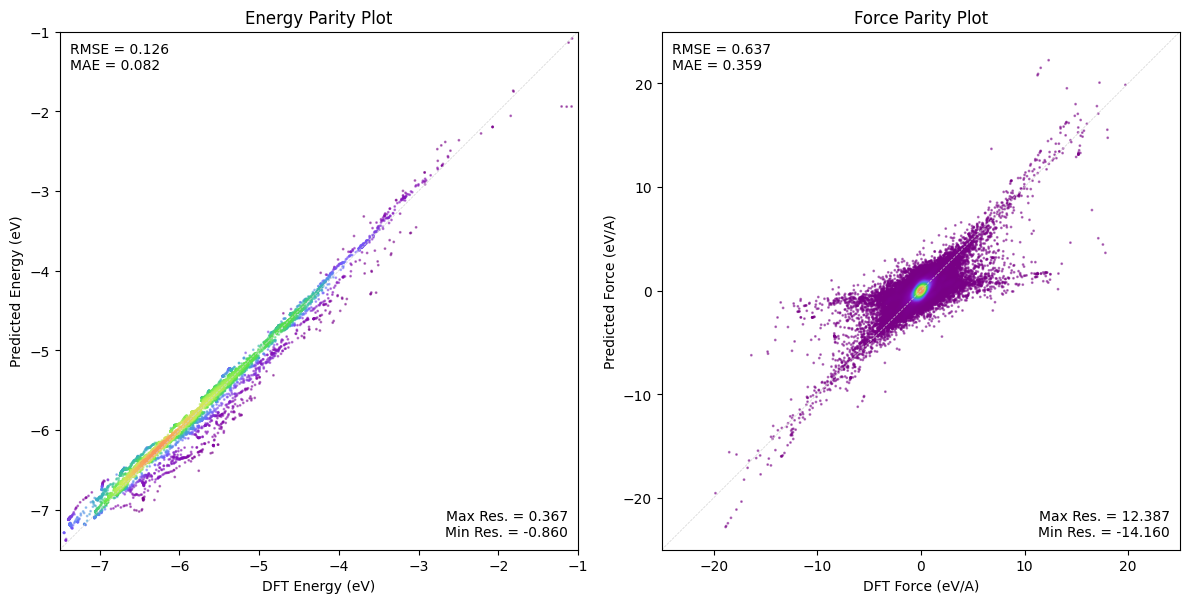

In [2]:
from uf3_handler import *
directories = ['/blue/ypchen/ntaormina/uf3/AlN/garun_7_9_2024_12_14_29/temp', '/blue/ypchen/ntaormina/uf3/AlN/pressure_variation_data', '/blue/ypchen/ntaormina/uf3/AlN/temp_variation_data']
run_data_path = '/blue/ypchen/ntaormina/uf3/AlN/garun_7_9_2024_12_14_29/run_data'
feature_filename = 'data/featurized/df_features_eah_2.h5'
data_filename = 'data/pickle_files/filtered/filtered_data_eah_2.pkl'
element_list = ['Al', 'N']
degree = 3
chemical_system = composition.ChemicalSystem(element_list=element_list,
                                             degree=degree)
r_min_map = {}
for pair in chemical_system.interactions_map[2]:
    r_min_map[pair] = 0.001
    
for trio in chemical_system.interactions_map[3]:
    r_min_map[trio] = [1.5,1.5,1.5]
r_max_map = {}
for pair in chemical_system.interactions_map[2]:
    r_max_map[pair] = 7.0
    
for trio in chemical_system.interactions_map[3]:
    r_max_map[trio] = [3.5,3.5,7.0]
r_resolution_map = {}
for pair in chemical_system.interactions_map[2]:
    r_resolution_map[pair] = 25
    
for trio in chemical_system.interactions_map[3]:
    r_resolution_map[trio] = [8,8,16]
trailing_trim = 3
leading_trim = 0
maps = {}
maps['r_min_map'] = r_min_map
maps['r_max_map'] = r_max_map
maps['r_resolution_map'] = r_resolution_map
maps['trailing_trim'] = trailing_trim
maps['leading_trim'] = leading_trim
regularizer =  dict(ridge_1b=1e-6,
                    ridge_2b=0.0,
                    ridge_3b=1e-6,
                    curvature_2b=5e-7,
                    curvature_3b=1e-7)

data_coordinator = io.DataCoordinator()
data_parser = DataParser(directories, data_coordinator)
data_parser.load_from_pickle(data_filename)
#featurizer = Featurizer(data_parser.get_data(), chemical_system, maps)
#featurizer.featurize_data(14, feature_filename + "test", 500)
#feature_filename = feature_filename + "test"
trainer = ModelTrainer(data_parser.get_data(), chemical_system, maps, regularizer) 
trainer.split_data(0.2)
trainer.train_model(feature_filename, weight=0.3, batch_size=2500)
trainer.export_model("test_model")

analyzer = ModelAnalyzer(chemical_system, trainer.get_model(), trainer.get_bspline_config(), trainer.get_training_set(), trainer.get_testing_set(), feature_filename)
analyzer.analyze_model(training=False)
analyzer.analyze_model(training=True)


In [21]:
feature_filename = 'df_features_N70_eah_2_force_5.h5'
filtered_data_filename = 'filtered_structure_data.pkl'


eah = 2
forceThreshold = 15

# ---------------OBEJCT INITIALIZATION----------------
structure_directories = ['/blue/ypchen/ntaormina/uf3/AlN/garun_7_9_2024_12_14_29/temp']
pressure_directories = ['/blue/ypchen/ntaormina/uf3/AlN/pressure_variation_data']
temp_directories = ['/blue/ypchen/ntaormina/uf3/AlN/temp_variation_data']
data_coordinator = io.DataCoordinator()
data_parser = DataParser(structure_directories, data_coordinator)
pressure_parser = DataParser(pressure_directories, data_coordinator)
temp_parser = DataParser(temp_directories, data_coordinator)
model_filename = filtered_data_filename + '.json'

#rundatapde = RunDataPhaseDiagram(run_data_path)
maps = {}
maps['r_min_map'] = r_min_map
maps['r_max_map'] = r_max_map
maps['r_resolution_map'] = r_resolution_map
maps['trailing_trim'] = trailing_trim
maps['leading_trim'] = leading_trim

# ---------------DATA PARSING----------------
# data_parser.parse_directories(output=False)
# data_parser.export_to_pickle('data_structures.pkl')
data_parser.load_from_pickle('data/pickle_files/data_structures.pkl')
# pressure_parser.parse_directories(output=True)
# pressure_parser.export_to_pickle('data_pressure.pkl')
pressure_parser.load_from_pickle('data/pickle_files/data_pressure.pkl')
# temp_parser.parse_directories(output=True)
# temp_parser.export_to_pickle('data_temp.pkl')
temp_parser.load_from_pickle('data/pickle_files/data_temp.pkl')
print(f"Length of structure data: {len(data_parser.get_data())}")
print(f"Length of pressure data: {len(pressure_parser.get_data())}")
print(f"Length of temperature data: {len(temp_parser.get_data())}")
sp = StructureParser(data_parser.get_data())
sda = DataSetAnalyzer(sp.get_data())
# pda = DataSetAnalyzer(pressure_parser.get_data())
# tda = DataSetAnalyzer(temp_parser.get_data())

structure_filter = DataFilter(sp.get_data())
print(f"Original Data Length: {len(structure_filter.get_data())}")
#structure_filter.filter_composition('N', 0.7)
#structure_filter.filter_energy_above_hull(eah)
#structure_filter.filter_force(forceThreshold,forceThreshold,forceThreshold)
#structure_filter.export_to_pickle(filtered_data_filename)
#structure_featurizer = Featurizer(sp.get_data(), chemical_system, maps)
# pressure_featurizer = Featurizer(pda.get_data(), chemical_system, maps)
# temp_featurizer = Featurizer(tda.get_data(), chemical_system, maps)
#structure_featurizer.featurize_data(num_cores=30, output_filename='data/df_features_structure.h5', batch_size=500)
# pressure_featurizer.featurize_data(num_cores=30, output_filename='data/df_features_pressure.h5', batch_size=500)
# temp_featurizer.featurize_data(num_cores=30, output_filename='data/df_features_temp.h5', batch_size=500)

# sp = StructureParser(data_parser.get_data())
# print(f"Original Data Length: {len(sp.get_data())}")
# filter = DataFilter(sp.get_data())
# filter.filter_composition('N', 0.6)
# print(f"Filtered Data Length: {len(filter.get_data())}")
# filter.filter_energy_above_hull(eah)
# filter.filter_force(forceThreshold,forceThreshold,forceThreshold)
# filtered_data = filter.get_data()
# print(f"Filtered Data Length: {len(filtered_data)}") 
# print(filtered_data.head())
# filter.export_to_pickle(filtered_data_filename)
# featurizer = Featurizer(filtered_data, chemical_system, maps)
# featurizer.featurize_data(num_cores=14, output_filename=feature_filename, batch_size=500)  
# regularizer =  dict(ridge_1b=1e-6,
#                     ridge_2b=0.0,
#                     ridge_3b=1e-6,
#                     curvature_2b=5e-7,
#                     curvature_3b=1e-7)
# trainer = ModelTrainer(data_parser.get_data(), chemical_system, maps, regularizer) 
# trainer.split_data(0.2)
# trainer.train_model(feature_filename, weight=0.3, batch_size=2500)
# trainer.export_model(model_filename)
# #trainer.import_model('model_test.json')

# analyzer = ModelAnalyzer(chemical_system, trainer.get_model(), trainer.get_bspline_config(), trainer.get_training_set(), trainer.get_testing_set(), feature_filename)
# analyzer.analyze_model(training=False)
# analyzer.analyze_model(training=True)

FileNotFoundError: [Errno 2] No such file or directory: 'data/pickle_files/data_structures.pkl'

In [ ]:
import os
import multiprocessing

# Using os module
num_cores_os = os.cpu_count()
print(f"Number of cores using os: {num_cores_os}")

# Using multiprocessing module
num_cores_mp = multiprocessing.cpu_count()
print(f"Number of cores using multiprocessing: {num_cores_mp}")
stop

Number of cores using os: 128
Number of cores using multiprocessing: 128


NameError: name 'stop' is not defined

In [ ]:
stop

In [ ]:
feature_filename = 'df_features_N60_eah_2_force_5.h5'
filtered_data_filename = 'filtered_data_N60_eah_2_force_5.pkl'


eah = 2
forceThreshold = 5

# ---------------OBEJCT INITIALIZATION----------------
data_coordinator = io.DataCoordinator()
data_parser = DataParser(directories, data_coordinator)
model_filename = filtered_data_filename + '.json'

#rundatapde = RunDataPhaseDiagram(run_data_path)
maps = {}
maps['r_min_map'] = r_min_map
maps['r_max_map'] = r_max_map
maps['r_resolution_map'] = r_resolution_map
maps['trailing_trim'] = trailing_trim
maps['leading_trim'] = leading_trim

# ---------------DATA PARSING----------------
# data_parser.parse_directories(output=False)
# data_parser.export_to_pickle('data_all.pkl')
data_parser.load_from_pickle('data_all.pkl')
print(f"Original Data Length: {len(data_parser.get_data())}")


sp = StructureParser(data_parser.get_data())
print(f"Original Data Length: {len(sp.get_data())}")
filter = DataFilter(sp.get_data())
filter.filter_composition('N', 0.6)
print(f"Filtered Data Length: {len(filter.get_data())}")
filter.filter_energy_above_hull(eah)
filter.filter_force(forceThreshold,forceThreshold,forceThreshold)
filtered_data = filter.get_data()
print(f"Filtered Data Length: {len(filtered_data)}") 
print(filtered_data.head())
filter.export_to_pickle(filtered_data_filename)
# featurizer = Featurizer(filtered_data, chemical_system, maps)
# featurizer.featurize_data(num_cores=14, output_filename=feature_filename, batch_size=500)  
# regularizer =  dict(ridge_1b=1e-6,
#                     ridge_2b=0.0,
#                     ridge_3b=1e-6,
#                     curvature_2b=5e-7,
#                     curvature_3b=1e-7)
# trainer = ModelTrainer(data_parser.get_data(), chemical_system, maps, regularizer) 
# trainer.split_data(0.2)
# trainer.train_model(feature_filename, weight=0.3, batch_size=2500)
# trainer.export_model(model_filename)
# #trainer.import_model('model_test.json')

# analyzer = ModelAnalyzer(chemical_system, trainer.get_model(), trainer.get_bspline_config(), trainer.get_training_set(), trainer.get_testing_set(), feature_filename)
# analyzer.analyze_model(training=False)
# analyzer.analyze_model(training=True)

In [ ]:
stop

In [ ]:
import nbformat
from nbconvert import HTMLExporter
from nbconvert.preprocessors import ExecutePreprocessor
from IPython.display import display, HTML
import sys

def run_notebook_with_current_kernel(notebook_path):
    # Get the current Python executable path
    current_kernel_path = sys.executable

    # Read the notebook
    with open(notebook_path) as f:
        nb = nbformat.read(f, as_version=4)

    # Modify the kernel spec in the notebook to use the current kernel
    nb['metadata']['kernelspec'] = {
        'name': 'python3',
        'display_name': 'Python 3 (current)',
        'argv': [
            current_kernel_path,
            '-m', 'ipykernel_launcher',
            '-f', '{connection_file}'
        ]
    }

    # Create an ExecutePreprocessor with the same kernel
    ep = ExecutePreprocessor(timeout=600, kernel_name='python3')

    # Execute the notebook
    ep.preprocess(nb, {'metadata': {'path': './'}})

    # Optionally, convert notebook to HTML to display
    exporter = HTMLExporter()
    body, _ = exporter.from_notebook_node(nb)

    return nb, body

# Example usage
notebook_path = 'Parse_AlN.ipynb'
nb, html_output = run_notebook_with_current_kernel(notebook_path)

# Display the results
display(HTML(html_output))
